# 🧠 MODEL LSTM (FINAL) — Prediksi Volatilitas Return Saham
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🔧 Versi final — konsisten dgn XGBoost
- **Set fitur identik (28)** dgn XGBoost final (termasuk 8 fitur sentimen) → perbandingan RM-3 sah.
- Arsitektur LSTM 2-lapis (64→32) + BatchNorm + Dropout, **lookback=10**, `shuffle=False`.
- Evaluasi pada **skala volatilitas asli** (inverse-transform). Reprodusibel (seed tetap).
- Output → `lstm_best_{emiten}.keras`, `tabel_evaluasi_lstm.csv`, `hasil_prediksi_lstm.csv`, gambar.

## ⚙️ CELL 1 — Import, Konfigurasi, Feature Set

In [4]:
import os
import warnings
import random
from pathlib import Path

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

warnings.filterwarnings('ignore')

# ============================================================
# SEED
# ============================================================
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 11,
    'figure.dpi': 150
})

# ============================================================
# ROOT PATH
# ============================================================
ROOT = Path(os.getcwd())

for _ in range(6):
    if (ROOT / '03_dataset').exists():
        break
    ROOT = ROOT.parent

if not (ROOT / '03_dataset').exists():
    ROOT = Path(
        r'e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
        r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026'
    )

DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_MODEL  = ROOT / '04_model' / 'lstm'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'

for d in (DIR_MODEL, DIR_TABEL, DIR_GAMBAR):
    d.mkdir(parents=True, exist_ok=True)

# ============================================================
# CONFIG
# ============================================================
URUTAN_EMITEN = ['ADRO','ADMR','ITMG','PTBA','MEDC','AKRA','PGAS']

KOLOM_Y  = 'Volatilitas'

LOOKBACK = 10
EPOCHS   = 100
BATCH    = 16
PATIENCE = 20
LR       = 1e-4

# ============================================================
# FEATURES (34 TOTAL)
# ============================================================
KOLOM_X_KANDIDAT = [

    # ===== Base =====
    'Close',
    'Log_Return',

    # ===== Volatility Features (NEW) =====
    'Volatilitas_Return',
    'Vol_Lag1',
    'Vol_Lag2',
    'Vol_Lag3',
    'Vol_MA5',
    'Vol_STD5',

    # ===== Technical Indicators =====
    'MA5',
    'MA10',
    'MA20',
    'EMA12',
    'EMA26',
    'RSI14',
    'MACD',
    'MACD_Signal',
    'MACD_Hist',
    'BB_Upper',
    'BB_Lower',
    'BB_Width',
    'BB_PctB',
    'Stoch_K',
    'Stoch_D',
    'Volume',
    'Volume_Change',
    'Volume_MA5',

    # optional
    # 'Volume_ZScore',

    # ===== Sentiment =====
    'Skor_Sentimen',
    'N_Berita',
    'Ada_Berita',
    'Skor_Sentimen_Lag1',
    'Skor_Sentimen_Lag2',
    'Sentiment_MA3',
    'Sentiment_MA20',
    'Sentiment_STD20'
]

# ============================================================
# VALIDASI FEATURE
# ============================================================
assert len(KOLOM_X_KANDIDAT) == 34, \
    f"Jumlah fitur salah: {len(KOLOM_X_KANDIDAT)} (harus 34)"

print('=' * 75)
print('✅ LSTM CONFIG READY')
print('=' * 75)
print(f'ROOT            : {ROOT}')
print(f'TensorFlow      : {tf.__version__}')
print(f'Lookback        : {LOOKBACK}')
print(f'Epochs          : {EPOCHS}')
print(f'Batch Size      : {BATCH}')
print(f'Learning Rate   : {LR}')
print(f'Total Features  : {len(KOLOM_X_KANDIDAT)}')
print('=' * 75)

✅ LSTM CONFIG READY
ROOT            : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
TensorFlow      : 2.21.0
Lookback        : 10
Epochs          : 100
Batch Size      : 16
Learning Rate   : 0.0001
Total Features  : 34


## 🔧 CELL 2 — Fungsi Bantu

In [5]:
# ── Fungsi bantu: inverse-transform & metrik (skala volatilitas ASLI) ──
def inverse_transform(nilai, scaler_df, kolom=KOLOM_Y):
    """Kembalikan nilai ter-MinMax-scale ke skala asli. Konsisten utk XGBoost & LSTM."""
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min']); cmax = float(scaler_df.loc[kolom, 'max'])
    return np.asarray(nilai, dtype=float) * (cmax - cmin) + cmin

def _mape(y, p, eps=1e-8):
    y=np.asarray(y,float); p=np.asarray(p,float); m=np.abs(y)>eps
    return np.nan if m.sum()==0 else float(np.mean(np.abs((y[m]-p[m])/y[m]))*100)

def _smape(y, p, eps=1e-8):
    y=np.asarray(y,float); p=np.asarray(p,float); d=np.abs(y)+np.abs(p); m=d>eps
    return np.nan if m.sum()==0 else float(np.mean(2*np.abs(p[m]-y[m])/d[m])*100)

def _qlike(y, p, eps=1e-12):
    ht=np.maximum(np.asarray(y,float)**2,eps); hp=np.maximum(np.asarray(p,float)**2,eps)
    return float(np.mean(np.log(hp)+ht/hp))

def evaluasi_semua_metrik(y_true, y_pred):
    return {
        'RMSE' : float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE'  : float(mean_absolute_error(y_true, y_pred)),
        'MAPE (%)' : round(_mape(y_true, y_pred), 2),
        'sMAPE (%)': round(_smape(y_true, y_pred), 2),
        'R2'   : round(float(r2_score(y_true, y_pred)), 4),
        'QLIKE': round(_qlike(y_true, y_pred), 4),
    }

def interpretasi_mape(m):
    if   m < 10: return 'Sangat Baik'
    elif m < 20: return 'Baik'
    elif m < 50: return 'Cukup'
    else       : return 'Kurang Baik'

print('✅ Fungsi bantu siap (evaluasi pada skala volatilitas asli).')

✅ Fungsi bantu siap (evaluasi pada skala volatilitas asli).


## 📂 CELL 3 — Load Dataset per Emiten (allowlist 28 fitur)

In [6]:
dict_train, dict_test, dict_scaler, dict_kolom_x = {}, {}, {}, {}

for emiten in URUTAN_EMITEN:
    p_tr = DIR_FINAL / f'dataset_train_{emiten}.csv'
    p_te = DIR_FINAL / f'dataset_test_{emiten}.csv'
    p_sc = DIR_FINAL / f'scaler_params_{emiten}.csv'
    if not p_tr.exists() or not p_te.exists():
        print(f'  ⚠️  {emiten}: file train/test tidak ditemukan, skip'); continue

    df_tr = pd.read_csv(p_tr, encoding='utf-8-sig')
    df_te = pd.read_csv(p_te, encoding='utf-8-sig')
    for d in (df_tr, df_te):
        if 'Date' in d.columns:
            d['Date'] = pd.to_datetime(d['Date'], errors='coerce')

    # ── ALLOWLIST: pilih fitur dari KOLOM_X_KANDIDAT yg ADA di train DAN test ──
    kolom_x = [c for c in KOLOM_X_KANDIDAT if c in df_tr.columns and c in df_te.columns]
    hilang  = [c for c in KOLOM_X_KANDIDAT if c not in kolom_x]

    df_tr = df_tr.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)
    df_te = df_te.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)
    scaler = pd.read_csv(p_sc, index_col=0, encoding='utf-8-sig') if p_sc.exists() else None

    dict_train[emiten]=df_tr; dict_test[emiten]=df_te
    dict_scaler[emiten]=scaler; dict_kolom_x[emiten]=kolom_x

    ket_h = f' | ⚠️ fitur hilang: {hilang}' if hilang else ''
    print(f'  ✅ {emiten}: train={len(df_tr):,} | test={len(df_te):,} | '
          f'fitur={len(kolom_x)} | sentimen={"Skor_Sentimen" in kolom_x}{ket_h}')

n_fitur_set = {len(v) for v in dict_kolom_x.values()}
print(f'\n  Total emiten: {len(dict_train)} | jumlah fitur per emiten: {n_fitur_set}')
if len(n_fitur_set) > 1:
    print('  ⚠️  Jumlah fitur antar-emiten berbeda — periksa kelengkapan kolom CSV.')

  ✅ ADRO: train=835 | test=209 | fitur=34 | sentimen=True
  ✅ ADMR: train=830 | test=207 | fitur=34 | sentimen=True
  ✅ ITMG: train=834 | test=207 | fitur=34 | sentimen=True
  ✅ PTBA: train=835 | test=209 | fitur=34 | sentimen=True
  ✅ MEDC: train=835 | test=209 | fitur=34 | sentimen=True
  ✅ AKRA: train=834 | test=207 | fitur=34 | sentimen=True
  ✅ PGAS: train=835 | test=209 | fitur=34 | sentimen=True

  Total emiten: 7 | jumlah fitur per emiten: {34}


## 🔧 CELL 4 — Fungsi Sekuens & Arsitektur LSTM

In [7]:
def buat_sekuens(X, y, lookback=LOOKBACK):
    Xs, ys = [], []
    for t in range(lookback, len(X)):
        Xs.append(X[t-lookback:t, :]); ys.append(y[t])
    return np.array(Xs), np.array(ys)

def buat_model_lstm(n_fitur, lookback=LOOKBACK, u1=64, u2=32, dropout=0.2, lr=1e-3):
    model = Sequential([
        Input(shape=(lookback, n_fitur)),
        LSTM(u1, return_sequences=True, kernel_regularizer=keras.regularizers.l2(1e-4)),
        BatchNormalization(), Dropout(dropout),
        LSTM(u2, return_sequences=False, kernel_regularizer=keras.regularizers.l2(1e-4)),
        BatchNormalization(), Dropout(dropout),
        Dense(16, activation='relu'),
        Dense(1),
    ], name=f'LSTM_{u1}_{u2}')
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse', metrics=['mae'])
    return model

_n = len(dict_kolom_x[URUTAN_EMITEN[0]]) if dict_kolom_x else len(KOLOM_X_KANDIDAT)
buat_model_lstm(_n).summary()
print(f'\n  Input shape: (batch, {LOOKBACK}, {_n})')

Model: "LSTM_64_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 10, 64)         │        25,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 10, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,689 (151.13 KB)

 Trainable params: 38,497 (150.38 KB)

 Non-trainable params: 192 (768.00 B)


  Input shape: (batch, 10, 34)


## 🎯 CELL 5 — Training, Prediksi & Evaluasi per Emiten (skala asli)

In [9]:
dict_model_lstm = {}
dict_history = {}
dict_hasil_lstm = {}
list_eval = []

print('=' * 75)
print('🎯 TRAINING LSTM')
print('=' * 75)

for emiten in URUTAN_EMITEN:

    if emiten not in dict_train:
        continue

    df_tr = dict_train[emiten]
    df_te = dict_test[emiten]
    kolom_x = dict_kolom_x[emiten]
    scaler = dict_scaler[emiten]

    missing = [c for c in KOLOM_X_KANDIDAT if c not in kolom_x]
    if missing:
        print(f'❌ {emiten}: fitur hilang -> {missing}')
        continue

    n_fitur = len(kolom_x)

    X_tr = df_tr[kolom_x].values.astype(np.float32)
    y_tr = df_tr[KOLOM_Y].values.astype(np.float32)

    X_te = df_te[kolom_x].values.astype(np.float32)
    y_te = df_te[KOLOM_Y].values.astype(np.float32)

    Xs_tr, ys_tr = buat_sekuens(X_tr, y_tr, LOOKBACK)
    Xs_te, ys_te = buat_sekuens(X_te, y_te, LOOKBACK)

    if len(Xs_tr) < BATCH * 2:
        print(f'⚠️ {emiten}: data terlalu sedikit')
        continue

    if np.isnan(Xs_tr).any() or np.isnan(ys_tr).any():
        print(f'❌ {emiten}: ada NaN')
        continue

    split_idx = int(len(Xs_tr) * 0.85)

    X_train = Xs_tr[:split_idx]
    X_val   = Xs_tr[split_idx:]

    y_train = ys_tr[:split_idx]
    y_val   = ys_tr[split_idx:]

    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    model = buat_model_lstm(n_fitur)

    callbacks = [
        EarlyStopping(
            monitor='val_loss',
            patience=PATIENCE,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=7,
            min_lr=1e-6
        ),
        ModelCheckpoint(
            str(DIR_MODEL / f'lstm_best_{emiten}.keras'),
            save_best_only=True
        )
    ]

    hist = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH,
        callbacks=callbacks,
        verbose=0,
        shuffle=False
    )

    dict_model_lstm[emiten] = model
    dict_history[emiten] = hist.history

    tensor_uji = tf.convert_to_tensor(Xs_te, dtype=tf.float32)
    y_pred_scaled = model(tensor_uji, training=False).numpy().flatten()

    y_true = inverse_transform(ys_te, scaler)
    y_pred = np.clip(inverse_transform(y_pred_scaled, scaler), 0, None)

    metrik = evaluasi_semua_metrik(y_true, y_pred)

    dates = df_te['Date'].iloc[LOOKBACK:].reset_index(drop=True).values

    dict_hasil_lstm[emiten] = pd.DataFrame({
        'Date': dates,
        'Emiten': emiten,
        'Y_Aktual': y_true,
        'Y_Prediksi': y_pred,
        'Residual': y_true - y_pred
    })

    list_eval.append({
        'Emiten': emiten,
        **metrik,
        'Keterangan': interpretasi_mape(metrik['MAPE (%)'])
    })

    print(
        f"✅ {emiten} | Epoch={len(hist.history['loss'])} "
        f"| RMSE={metrik['RMSE']:.5f} "
        f"| MAPE={metrik['MAPE (%)']:.2f}% "
        f"| R2={metrik['R2']:.4f}"
    )

print()
print(f'Training selesai: {len(dict_model_lstm)} emiten')

🎯 TRAINING LSTM
✅ ADRO | Epoch=25 | RMSE=0.00909 | MAPE=34.52% | R2=-0.9475
✅ ADMR | Epoch=24 | RMSE=0.02402 | MAPE=45.24% | R2=-1.7779
✅ ITMG | Epoch=45 | RMSE=0.01159 | MAPE=88.86% | R2=-0.4244
✅ PTBA | Epoch=25 | RMSE=0.01004 | MAPE=60.23% | R2=-0.4841
✅ MEDC | Epoch=26 | RMSE=0.00789 | MAPE=18.83% | R2=0.3564
✅ AKRA | Epoch=26 | RMSE=0.00731 | MAPE=26.93% | R2=-0.5523
✅ PGAS | Epoch=31 | RMSE=0.00832 | MAPE=26.72% | R2=-0.0358

Training selesai: 7 emiten


## 📋 CELL 6 — Tabel Evaluasi (→ Tabel 4.X)

In [10]:
df_eval = pd.DataFrame(list_eval)
avg = {'Emiten':'RATA-RATA'}
for c in df_eval.columns:
    if c not in ('Emiten','Keterangan'): avg[c]=round(df_eval[c].mean(),6)
avg['Keterangan']='-'
df_eval = pd.concat([df_eval, pd.DataFrame([avg])], ignore_index=True)
df_eval.index = list(range(1,len(df_eval))) + ['—']; df_eval.index.name='No'

pd.set_option('display.width',200,'display.max_columns',None)
print(df_eval.to_string())
df_eval.to_csv(DIR_TABEL / 'tabel_evaluasi_lstm.csv', encoding='utf-8-sig')
print('\n💾 tabel_evaluasi_lstm.csv tersimpan')

       Emiten      RMSE       MAE   MAPE (%)  sMAPE (%)        R2          QLIKE   Keterangan
No                                                                                           
1        ADRO  0.009092  0.007419  34.520000  27.940000 -0.947500      -6.315000        Cukup
2        ADMR  0.024023  0.019451  45.240000  63.980000 -1.777900      -0.579100        Cukup
3        ITMG  0.011586  0.009118  88.860000  55.100000 -0.424400  950150.948100  Kurang Baik
4        PTBA  0.010044  0.007949  60.230000  53.410000 -0.484100      -5.495800  Kurang Baik
5        MEDC  0.007889  0.005638  18.830000  18.150000  0.356400      -5.888200         Baik
6        AKRA  0.007313  0.006117  26.930000  27.620000 -0.552300      -6.277600        Cukup
7        PGAS  0.008321  0.006015  26.720000  32.110000 -0.035800      -6.087300        Cukup
—   RATA-RATA  0.011181  0.008815  43.047143  39.758571 -0.552229  135731.472157            -

💾 tabel_evaluasi_lstm.csv tersimpan


## 📊 CELL 7 — Learning Curve (→ Gambar 4.X)

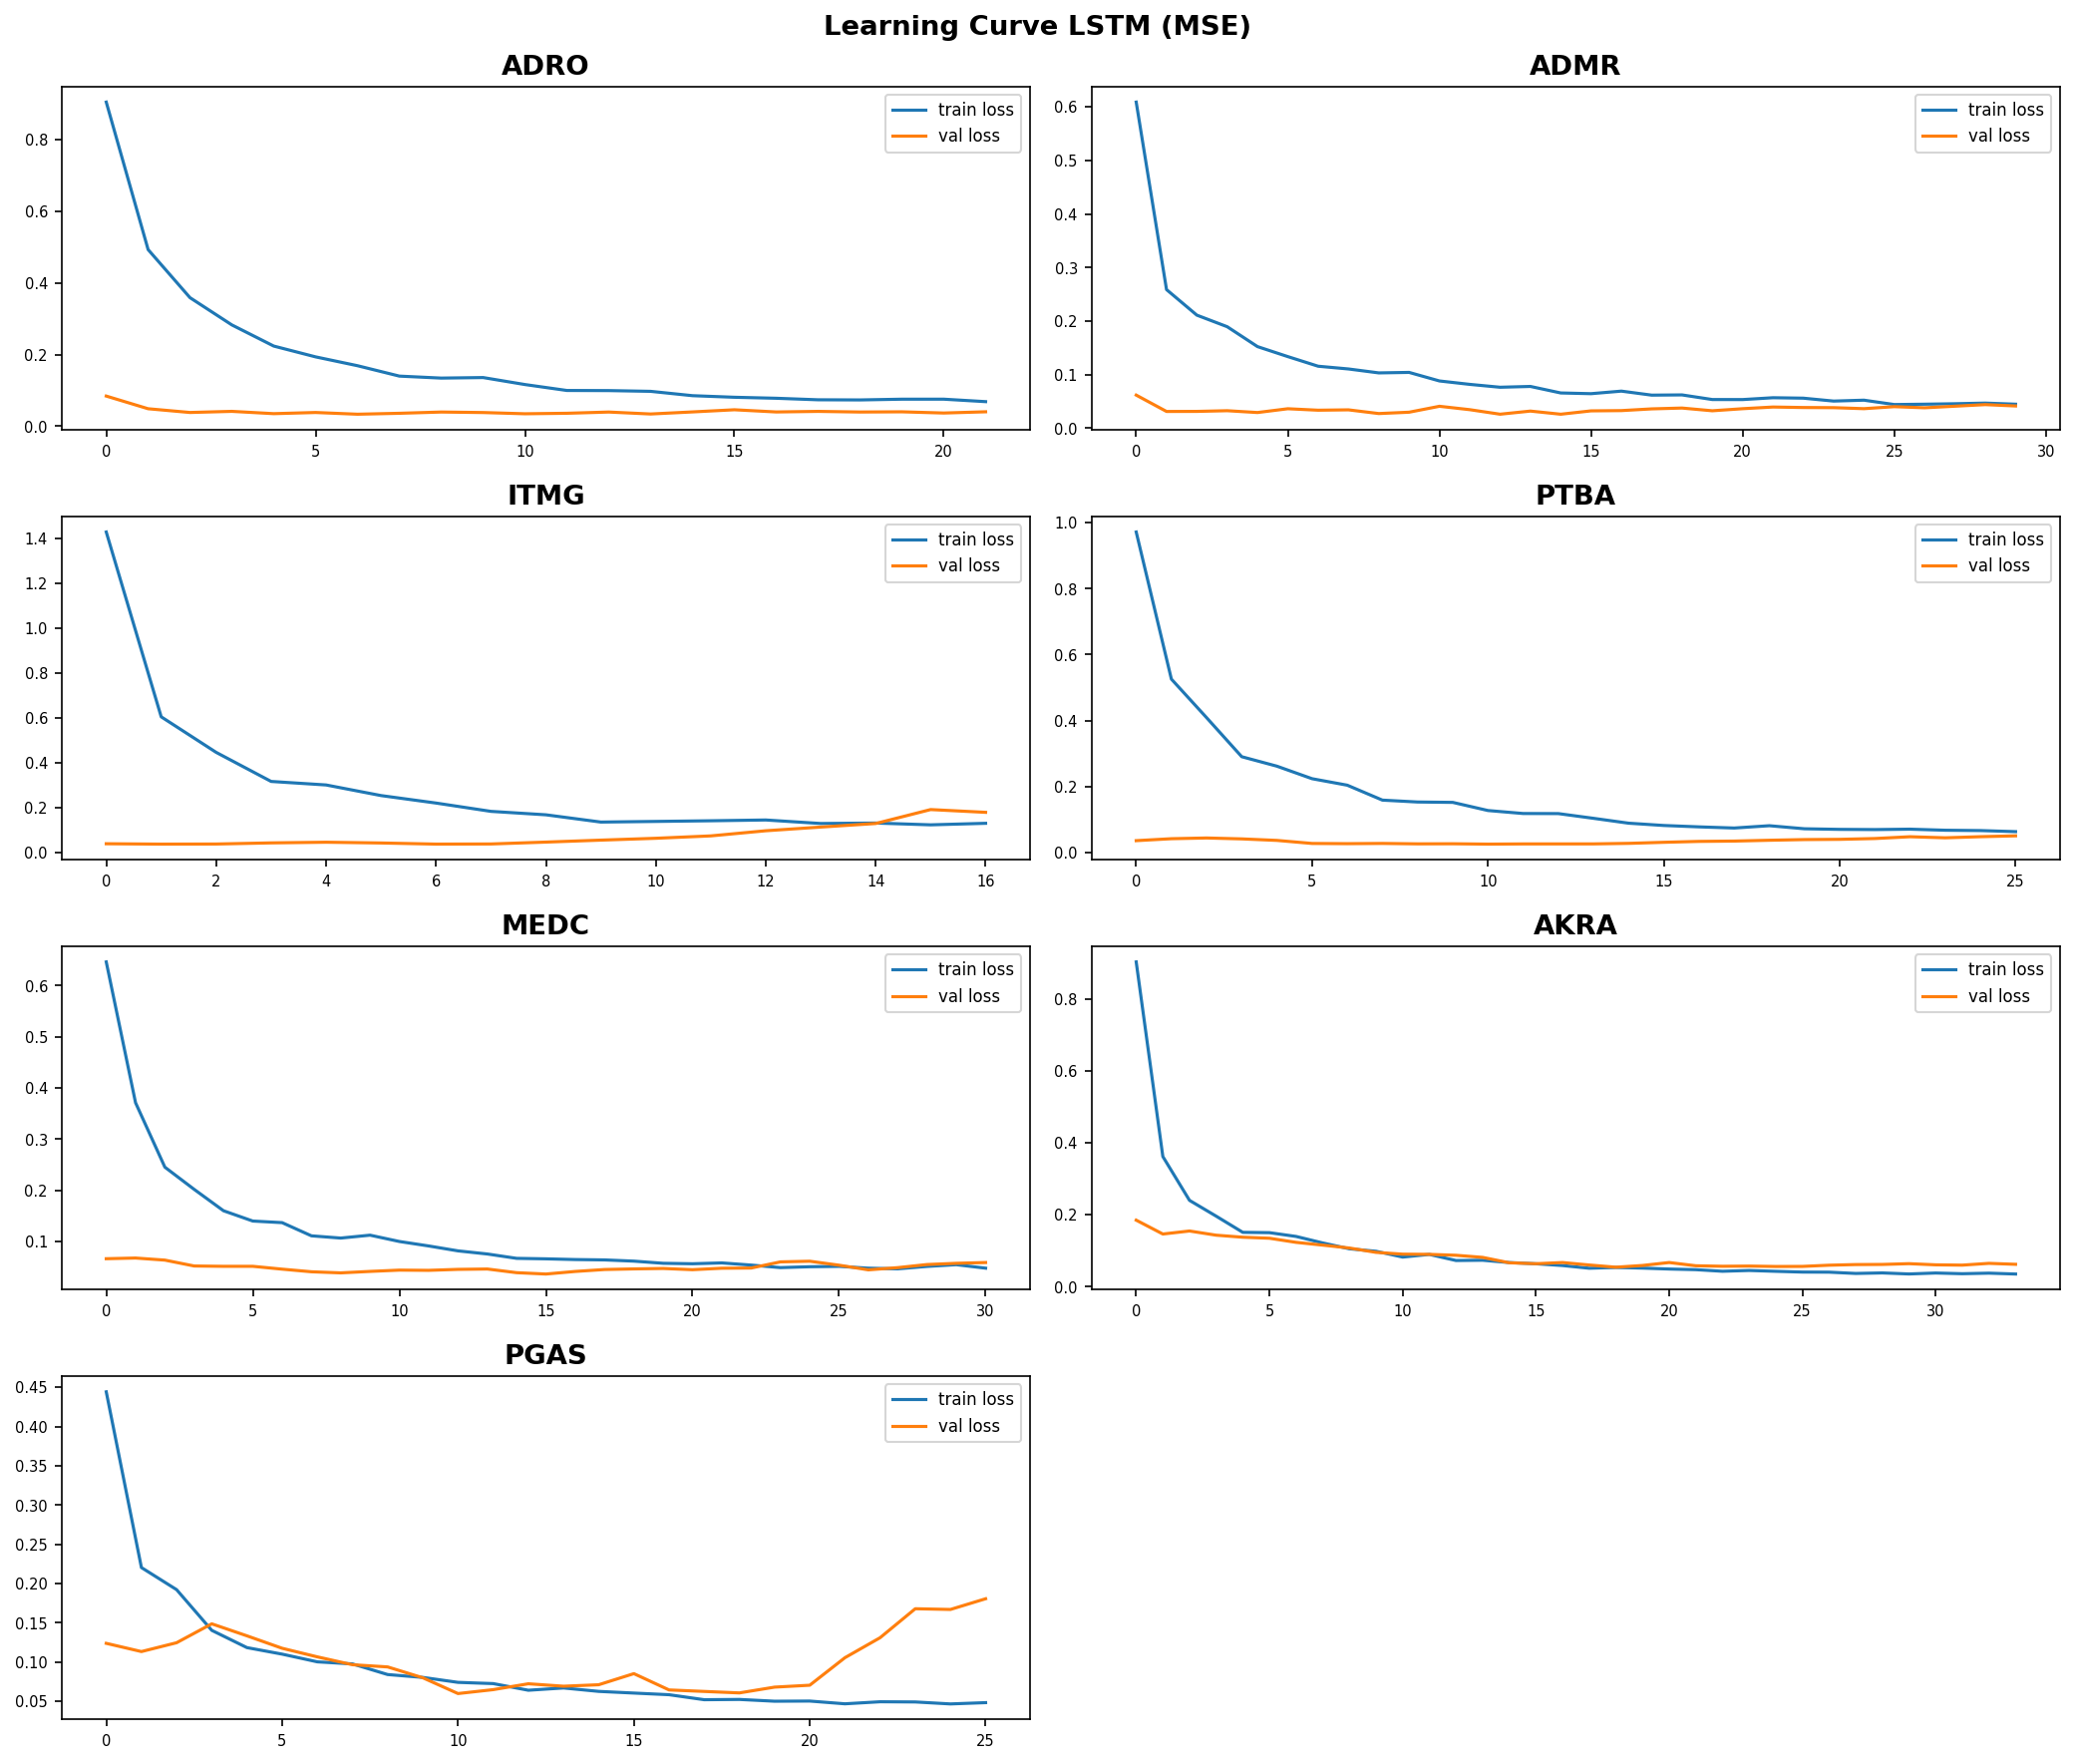

💾 learning curve tersimpan


In [18]:
emiten_ok = [e for e in URUTAN_EMITEN if e in dict_history]
ncol=2; nrow=int(np.ceil(len(emiten_ok)/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3*nrow)); axes=np.array(axes).ravel()
for ax, emiten in zip(axes, emiten_ok):
    h = dict_history[emiten]
    ax.plot(h['loss'], label='train loss'); ax.plot(h['val_loss'], label='val loss')
    ax.set_title(emiten, fontweight='bold'); ax.legend(fontsize=8); ax.tick_params(labelsize=7)
for ax in axes[len(emiten_ok):]: ax.axis('off')
plt.suptitle('Learning Curve LSTM (MSE)', fontweight='bold'); plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_lstm_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show(); print('💾 learning curve tersimpan')

## 📊 CELL 8 — Grafik Aktual vs Prediksi (→ Gambar 4.X)

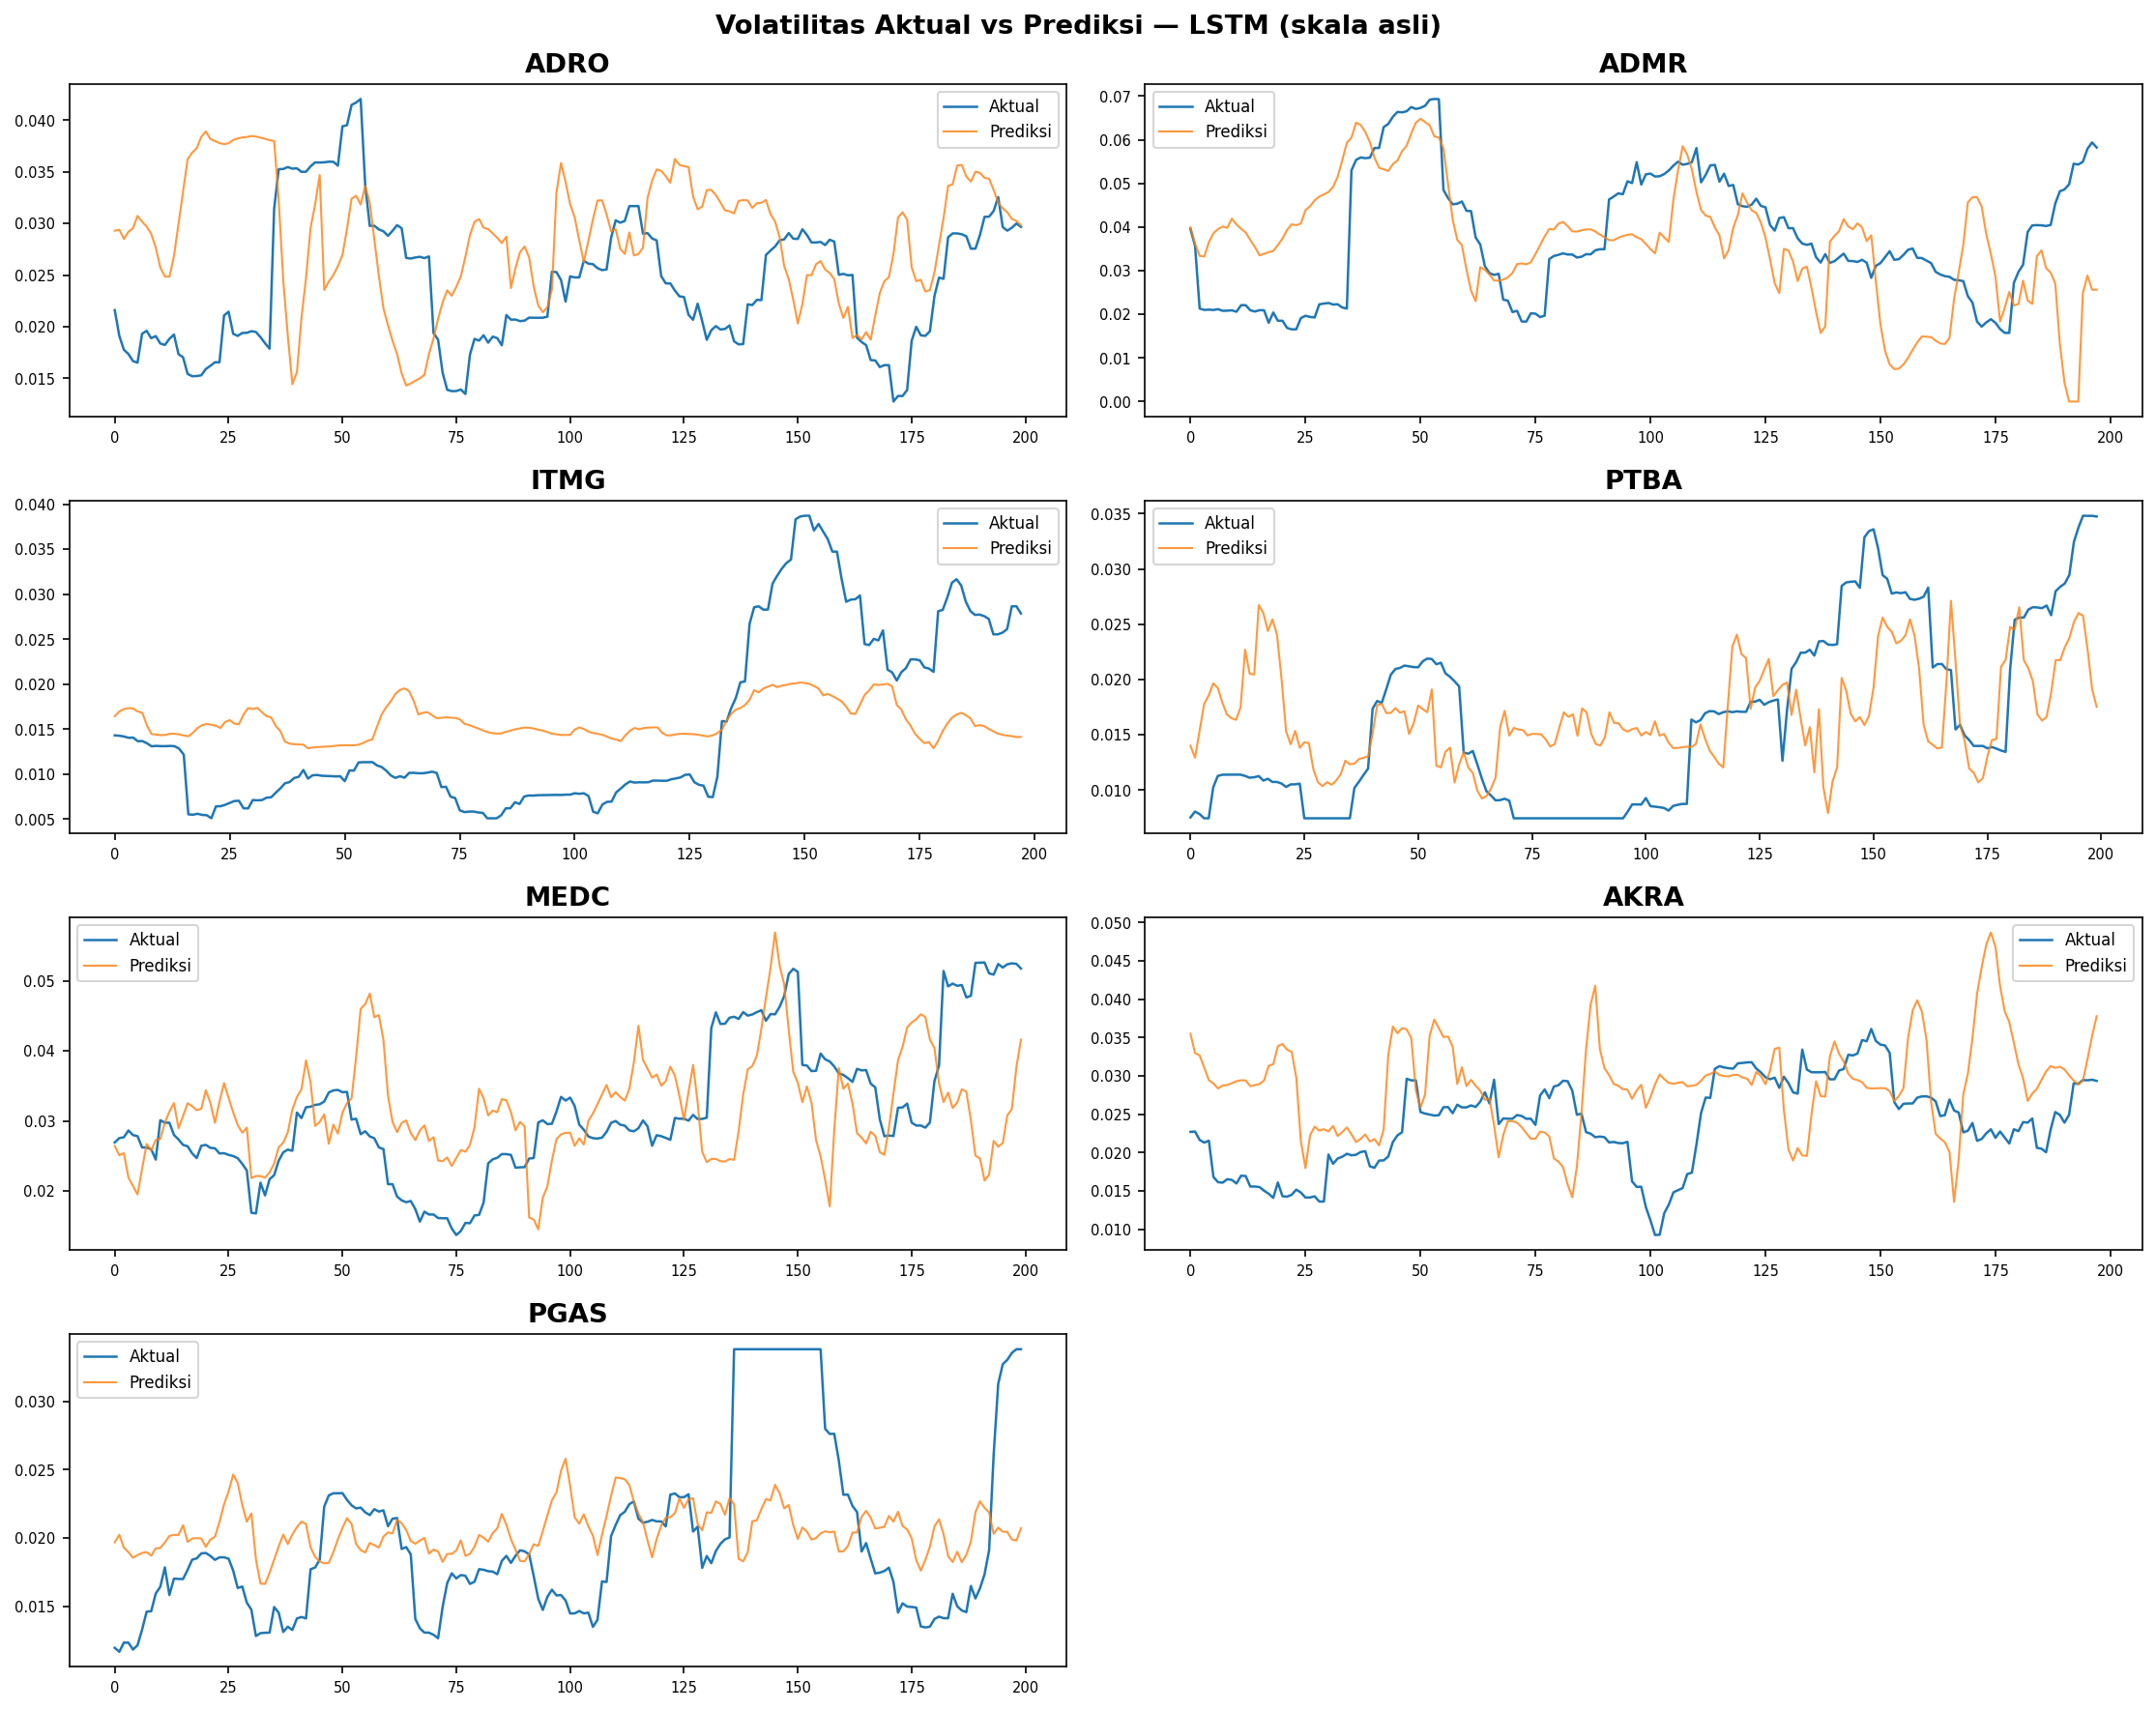

💾 gambar prediksi tersimpan


In [19]:
ncol=2; nrow=int(np.ceil(len(emiten_ok)/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3*nrow)); axes=np.array(axes).ravel()
for ax, emiten in zip(axes, emiten_ok):
    d = dict_hasil_lstm[emiten]
    ax.plot(d['Y_Aktual'].values, label='Aktual', lw=1.2)
    ax.plot(d['Y_Prediksi'].values, label='Prediksi', lw=1.0, alpha=0.8)
    ax.set_title(emiten, fontweight='bold'); ax.legend(fontsize=8); ax.tick_params(labelsize=7)
for ax in axes[len(emiten_ok):]: ax.axis('off')
plt.suptitle('Volatilitas Aktual vs Prediksi — LSTM (skala asli)', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_lstm_prediksi_per_emiten.png', dpi=150, bbox_inches='tight')
plt.show(); print('💾 gambar prediksi tersimpan')

## 💾 CELL 9 — Simpan Hasil Prediksi

In [20]:
df_all = pd.concat(dict_hasil_lstm.values(), ignore_index=True)
df_all.to_csv(DIR_TABEL / 'hasil_prediksi_lstm.csv', encoding='utf-8-sig', index=False)
print('='*70); print('✅ MODEL LSTM SELESAI')
print(f'  Hasil prediksi : hasil_prediksi_lstm.csv ({len(df_all):,} baris)')
print(f'  Model .keras   : {DIR_MODEL}')
print('  → Lanjut: jalankan EVALUASI_perbandingan.ipynb utk jawab RM-3')
print('='*70)

✅ MODEL LSTM SELESAI
  Hasil prediksi : hasil_prediksi_lstm.csv (1,394 baris)
  Model .keras   : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\04_model\lstm
  → Lanjut: jalankan EVALUASI_perbandingan.ipynb utk jawab RM-3
